Well use a GenericCascadeCase and we will load the example dataset, generated with OpenFOAM.
We don't necessarily need a complete dataset for postprocessing procedures.

In [6]:
from ntrfc.cascade_case.solution import GenericCascadeCase
import pyvista as pv
import importlib.resources


pv.set_jupyter_backend('trame')

inlet_path =  importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/inlet.vtp"
outlet_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/outlet.vtp"
blade_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/boundary/blade_wall.vtp"
fluid_path = importlib.resources.files("ntrfc") / "data/openfoam_cascade_case/internal.vtu"

case = GenericCascadeCase()

case.read_meshes(inlet_path,"inlet")
case.read_meshes(outlet_path,"outlet")
case.read_meshes(blade_path,"blade")
case.read_meshes(fluid_path,"fluid")


In [7]:

case.set_active_blade_slice()
case.compute_domainparams_from(0.01)

ratio of cleaned sites: 0.8360508152445734


/home/many/miniconda3/envs/NTRfC/lib/python3.10/site-packages/pyvista/core/filters/poly_data.py:2951: PyVistaFutureWarning: The default value of the ``capping`` keyword argument will change in a future version to ``True`` to match the behavior of VTK. We recommend passing the keyword explicitly to prevent future surprises.
  warnings.warn(


0

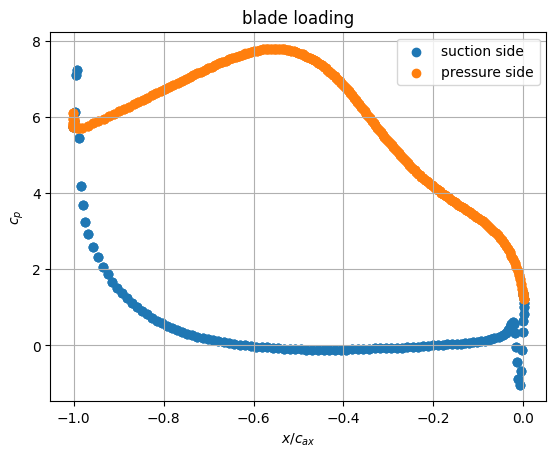

In [8]:
case.blade_loading(pressurevar="p", densityvar="rho", velvar="U")

In [9]:
avdr =case.compute_avdr_inout_massave()
print(avdr)


KeyError: 'Data array (UMean) not present in this dataset.'